# 隠れ状態にベクトルを足して生成の感情や文体を変える（アクティベーション・ステアリング）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/09_lm_analysis/activation_steering.ipynb)

NLP クックブック 09-08 ／ 言語モデルの確率と内部を調べる

> GPU ランタイム推奨（ランタイム → ランタイムのタイプを変更 → T4 GPU）

追加の学習をせずに、言語モデルの生成をポジティブな内容やです・ます調に寄せたい。対になる文（肯定的な文と否定的な文など）の隠れ状態の差の平均を「ステアリングベクトル」とし、生成のときに特定の層の出力（残差ストリーム）に足す。足す層と強さを変えて、感情分類器で効果を、パープレキシティと distinct-2 で文の崩れ方を測る。

In [1]:
!pip install -q matplotlib-fontja

In [2]:
import random
import numpy as np
import sentencepiece as spm
import torch
from huggingface_hub import hf_hub_download
from tokenizers import models
from transformers import AutoModelForCausalLM, AutoTokenizer

random.seed(0); np.random.seed(0); torch.manual_seed(0)

# SB Intuitions の Sarashina2.2-0.5B（指示チューニング前のベースモデル。MIT ライセンス）。この章の logit lens のレシピと同じモデル
name = "sbintuitions/sarashina2.2-0.5b"
tokenizer = AutoTokenizer.from_pretrained(name)
# transformers 5 系は、このモデルの SentencePiece (Unigram) を BPE に変換してしまい、学習時と違う分割になる。
# 元の tokenizer.model から語彙とスコアを読み、分割の方式だけを Unigram に戻す（特殊トークンやチャットテンプレートはそのまま）
sp = spm.SentencePieceProcessor(model_file=hf_hub_download(name, "tokenizer.model"))
tokenizer.backend_tokenizer.model = models.Unigram(
    [(sp.id_to_piece(i), sp.get_score(i)) for i in range(sp.get_piece_size())], unk_id=sp.unk_id(), byte_fallback=True)
tokenizer.padding_side = "left"                        # 複数のプロンプトをまとめて生成するので、パディングは左に入れる

BF16 = torch.cuda.get_device_capability()[0] >= 8      # bfloat16 は Ampere (A100, L4) 以降。T4 では float16 を使う
model = AutoModelForCausalLM.from_pretrained(name, dtype=torch.bfloat16 if BF16 else torch.float16, device_map="auto").eval()
n_layers = model.config.num_hidden_layers

# 対になる文: 感情だけが違い、ほかはなるべく同じにする（自作の例文）
pairs = [
    ("この映画は本当に素晴らしかった。", "この映画は本当にひどかった。"), ("店員さんがとても親切で嬉しかった。", "店員さんがとても無愛想で腹が立った。"),
    ("今日は最高の一日だった。", "今日は最悪の一日だった。"), ("料理はおいしくて大満足です。", "料理はまずくてがっかりです。"),
    ("新しい職場は楽しくて、毎日が充実している。", "新しい職場はつらくて、毎日が苦痛だ。"), ("この本を読んで心が温かくなった。", "この本を読んで気分が悪くなった。"),
    ("旅行は天気にも恵まれて、楽しい思い出になった。", "旅行は雨ばかりで、嫌な思い出になった。"), ("彼の発表はわかりやすくて感動した。", "彼の発表はわかりにくくて退屈だった。"),
    ("買ってよかったと心から思う。", "買わなければよかったと心から思う。"), ("試験に合格して、とても幸せだ。", "試験に落ちて、とても悲しい。"),
    ("友達と過ごす時間は本当に楽しい。", "友達と過ごす時間は本当に面倒だ。"), ("このホテルは清潔で快適だった。", "このホテルは汚くて不快だった。"),
    ("子どもたちの笑顔に元気をもらった。", "子どもたちの騒ぎ声にうんざりした。"), ("サービスが丁寧で、また来たいと思った。", "サービスが雑で、二度と来たくないと思った。"),
    ("春の公園は花が咲いていて気持ちがいい。", "春の公園は人が多くて気分が悪い。"), ("この曲を聴くと幸せな気持ちになる。", "この曲を聴くと憂うつな気持ちになる。"),
    ("引っ越し先の近所の人はみんな優しい。", "引っ越し先の近所の人はみんな冷たい。"), ("久しぶりに会えて、本当に嬉しかった。", "久しぶりに会ったのに、本当に気まずかった。"),
    ("この靴は軽くて歩きやすい。", "この靴は重くて歩きにくい。"), ("プレゼントをもらって、すごく喜んだ。", "プレゼントを忘れられて、すごく落ち込んだ。"),
    ("先生のおかげで勉強が好きになった。", "先生のせいで勉強が嫌いになった。"), ("このアプリは便利で手放せない。", "このアプリは不便で使う気にならない。"),
    ("駅のそばに素敵なカフェを見つけた。", "駅のそばのカフェで嫌な目にあった。"), ("みんなの協力で、イベントは大成功だった。", "準備不足で、イベントは大失敗だった。"),
]
# 方向が文の感情を表しているかを確かめるための別の文（ベクトルの計算には使わない）
test_pos = ["週末の遠足はとても楽しかった。", "この店のケーキは絶品だ。", "新しい部屋は明るくて気に入っている。", "息子が元気に育っていて嬉しい。",
            "親切な人に道を教えてもらって助かった。", "このドラマは毎回わくわくする。", "温泉に入って疲れがすっかり取れた。", "念願のチームに入れて夢のようだ。"]
test_neg = ["週末の遠足は散々だった。", "この店のケーキは食べられたものではない。", "新しい部屋は暗くて気がめいる。", "息子が熱を出して心配でたまらない。",
            "道に迷って、約束に遅れてしまった。", "このドラマは毎回退屈だ。", "満員電車で押されて、くたくたになった。", "選考に落ちて、何もする気が起きない。"]

@torch.no_grad()
def states(texts):
    """各文の隠れ状態の、トークン（先頭の BOS を除く）についての平均（文の数、層 0〜24、次元）と、トークンごとの大きさ（ノルム）の平均（層 0〜24）"""
    means, norms = [], []
    for t in texts:
        ids = tokenizer(tokenizer.bos_token + t, add_special_tokens=False, return_tensors="pt")["input_ids"].to(model.device)
        hs = torch.stack(model(ids, output_hidden_states=True).hidden_states)[:, 0, 1:].float()   # （層、トークン、次元）
        means.append(hs.mean(1)); norms.append(hs.norm(dim=-1).mean(1))
    return torch.stack(means), torch.stack(norms).mean(0)

pos, pos_norm = states([p for p, _ in pairs])
neg, neg_norm = states([n for _, n in pairs])
steer_vec = (pos - neg).mean(0)                        # 層ごとのステアリングベクトル（対の差の平均）: （層 0〜24、次元）
h_norm = (pos_norm + neg_norm) / 2                     # 層ごとの隠れ状態の大きさの目安（足す強さの基準にする）
print("隠れ状態の大きさ（層 0, 3, 6, 12, 18, 23）:", [round(h_norm[l].item(), 1) for l in [0, 3, 6, 12, 18, 23]])
print("ベクトルの大きさ / 隠れ状態の大きさ（同じ層）:", [round((steer_vec[l].norm() / h_norm[l]).item(), 2) for l in [0, 3, 6, 12, 18, 23]])
# 上の平均から除いた先頭の BOS の位置は、層によっては大きさがほかの位置とまったく違う
with torch.no_grad():
    ids = tokenizer(tokenizer.bos_token + pairs[0][0], add_special_tokens=False, return_tensors="pt")["input_ids"].to(model.device)
    hs_bos = model(ids, output_hidden_states=True).hidden_states
print("BOS の位置の隠れ状態の大きさ（層 0, 3, 6, 12, 18, 23）:", [round(hs_bos[l][0, 0].float().norm().item(), 1) for l in [0, 3, 6, 12, 18, 23]])

隠れ状態の大きさ（層 0, 3, 6, 12, 18, 23）: [9.1, 14.1, 15.9, 20.0, 30.2, 47.7]
ベクトルの大きさ / 隠れ状態の大きさ（同じ層）: [0.1, 0.12, 0.13, 0.17, 0.19, 0.18]
BOS の位置の隠れ状態の大きさ（層 0, 3, 6, 12, 18, 23）: [16.4, 7024.2, 8454.9, 9415.8, 9415.8, 9416.0]


別の 16 文の正解率（層 0〜24。層 24 は最終の正規化の後）: 0.88 0.81 0.88 0.88 0.94 0.94 0.94 0.94 0.94 0.94 0.94 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 0.88


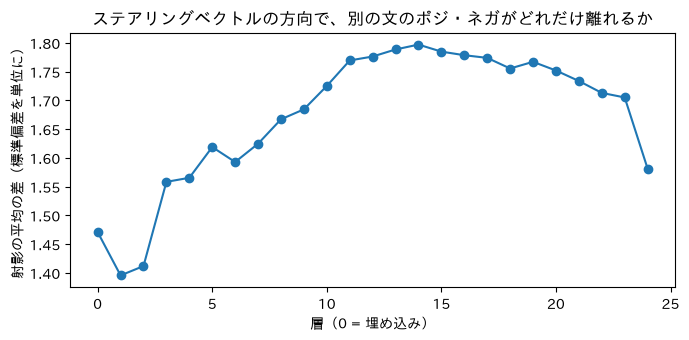

層  6  + 方向: ['iceship', 'rtered', ' smiles', ' warmth', '本当に素晴らしい', ' blessed', 'unlocked', ' enjoyed', '幸せになれる', ' gifts']
        − 方向: [' worse', ' CAUSED', 'Worse', '惧', 'がひどい', ' DAMAGE', 'がひどく', 'の被害', ' noqa', 'ひどい']
層 12  + 方向: [' warmth', 'のは嬉しい', '感謝', ' enjoyed', ' shining', ' joyful', '🥰', ' marvell', ' joyous', ' smiles']
        − 方向: [' worse', 'Worse', 'がひどい', 'を避けるために', 'が酷い', ' CAUSED', 'ひどい', '酷い', 'が酷く', 'がひどく']
層 18  + 方向: [' warmth', ' enjoyed', 'とても嬉しい', '嬉しいです', '嬉しいですね', '嬉しかったです', '素敵な', '感謝', ' joyful', 'のも嬉しい']
        − 方向: [' worse', 'Worse', 'を避けるために', 'がひどい', 'を避けるため', 'が酷い', 'を悪化させ', 'になりかねない', 'を回避する', 'が酷く']


In [3]:
import matplotlib.pyplot as plt
import matplotlib_fontja  # import するだけで日本語のフォントが使える

# 確認 1: ベクトルの方向への射影で、別の文のポジ・ネガを分けられるか（差の平均を方向にした、ごく単純な線形のプローブ）
tp, _ = states(test_pos)
tn, _ = states(test_neg)
acc, gap = [], []
for l in range(n_layers + 1):
    v = steer_vec[l] / steer_vec[l].norm()
    threshold = ((pos[:, l] @ v).mean() + (neg[:, l] @ v).mean()) / 2   # しきい値も対の文から決める
    proj_pos, proj_neg = tp[:, l] @ v, tn[:, l] @ v   # 別の文のポジ・ネガそれぞれの射影
    acc.append(((proj_pos > threshold).float().mean() + (proj_neg <= threshold).float().mean()).item() / 2)
    gap.append(((proj_pos.mean() - proj_neg.mean()) / torch.cat([proj_pos, proj_neg]).std()).item())   # 2 群の平均の差（標準偏差を単位に）
print("別の 16 文の正解率（層 0〜24。層 24 は最終の正規化の後）:", " ".join(f"{a:.2f}" for a in acc))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(gap, "o-"); ax.set_xlabel("層（0 = 埋め込み）"); ax.set_ylabel("射影の平均の差（標準偏差を単位に）")
ax.set_title("ステアリングベクトルの方向で、別の文のポジ・ネガがどれだけ離れるか")
plt.tight_layout(); plt.show()

# 確認 2: ベクトルを logit lens と同じく最終層の正規化と出力層で読むと、どのトークンを押し上げる方向か
for l in [6, 12, 18]:
    logits = model.lm_head(model.model.norm(steer_vec[l].to(model.dtype))).float()
    up, down = logits.topk(10).indices, (-logits).topk(10).indices
    print(f"層 {l:2}  + 方向: {[tokenizer.decode(i) for i in up]}\n        − 方向: {[tokenizer.decode(i) for i in down]}")

In [4]:
import contextlib

@contextlib.contextmanager
def steering(vec, layer, alpha):
    """with の中では、層 layer (1〜23) の出力（残差ストリーム）に、隠れ状態の大きさの alpha 倍の長さにした vec を足す"""
    add = (vec[layer] / vec[layer].norm() * h_norm[layer] * alpha).to(model.dtype)
    def hook(module, inputs, output):
        return output + add                            # transformers 5 の Llama 系では、層の出力は隠れ状態のテンソル。戻り値で置き換わる
    # model.model.layers[l - 1] の出力が hidden_states[l]（層 l）にあたる。プロンプトと生成したトークンのすべての位置に足す
    # （BOS とパディングの位置にも足すが、層 3 以降の BOS の隠れ状態はほかの位置よりずっと大きく（ベクトルを作るセルの出力）、パディングはアテンションで無視されるので、影響は小さいと考えられる）
    handle = model.model.layers[layer - 1].register_forward_hook(hook)
    try:
        yield
    finally:
        handle.remove()                                # 外し忘れると、以後のすべての計算にベクトルが足され続ける

prompts = ["昨日、駅前の新しいレストランに行った。", "先週から新しい仕事を始めた。", "今日は朝から雨が降っていた。", "この前、友達と映画を見に行った。",
           "週末に家族で海へ出かけた。", "最近、新しいスマートフォンを買った。", "今朝、電車の中で", "引っ越してから一か月がたった。",
           "久しぶりに実家に帰った。", "昨日の会議で、", "近所に新しいカフェができた。", "この本の感想を書く。",
           "今年の夏休みは", "兄から手紙が届いた。", "駅まで歩いていると、", "新しい先生が来た。",
           "昼ごはんにラーメンを食べた。", "午後から図書館で勉強した。", "初めて飛行機に乗った。", "今日の天気は"]
N_SAMPLES = 4                                          # プロンプトごとに 4 本、計 80 本を生成する

@torch.no_grad()
def generate(max_new_tokens=40, seed=0):
    enc = tokenizer([tokenizer.bos_token + p for p in prompts], add_special_tokens=False, padding=True, return_tensors="pt").to(model.device)
    torch.manual_seed(seed)                            # どの条件でも同じ乱数で生成し、違いをステアリングだけにする
    out = model.generate(**enc, do_sample=True, temperature=0.8, top_p=0.9, max_new_tokens=max_new_tokens,
                         num_return_sequences=N_SAMPLES, pad_token_id=tokenizer.pad_token_id)
    return [tokenizer.decode(o[enc["input_ids"].shape[1]:], skip_special_tokens=True) for o in out]

base = generate()
with steering(steer_vec, 12, 0.25):
    steered = generate()
for i in [0, 12, 40]:
    print(f"[{prompts[i // N_SAMPLES]}]\n  なし: {base[i]!r}\n  あり: {steered[i]!r}")

[昨日、駅前の新しいレストランに行った。]
  なし: '\nレストランは、広くてきれいだった。\n「きれいだった」は、きれいだった。\n「きれいだった」は、きれいだった。\n「きれいだった」は、きれいだった。\n「'
  あり: '\nレストランは、広くて、きれいで、とても気持ち良かったです。\n今日、僕は、新しい本を読んだ。\nこの本は、とても楽しくて、また、新しい本を買おうと思いました。\nA: How is it'
[この前、友達と映画を見に行った。]
  なし: '\nI saw a movie with my friends.\n「見に行った」は「見に行った」と「見た」の間に「行った」が入るので、文が過去形になる。\nI went to'
  あり: '僕は、この映画には、とても、わくわくした。でも、この映画を見た後は、もっと、わくわくした。この映画は、とても、おもしろいから、ぜひ、みんなに、見てほしい。\n（日本語）私は'
[近所に新しいカフェができた。]
  なし: '\n\n**質問4:**  \n「2人の子供を持つ家族」というフレーズは、2人の子供と1人の大人を含みます。このフレーズの3つの異なる表現の中で、最も一般的な表現'
  あり: '\n\n**質問4:**  \nテキストで説明されているように、Rプログラミング言語の主な目標は何ですか？\n\n**回答4:**  \nRプログラミング言語の主な目標は、Rのオープンソース'


In [5]:
import time
import pandas as pd
from transformers import pipeline

# 評価 1: 感情分類器（テキスト分類の章の「日本語の感情分析（ポジネガ判定）をする」と同じ多言語モデル。Apache 2.0）。
# スコアは P(positive) − P(negative) で、−1〜+1
clf = pipeline("text-classification", model="lxyuan/distilbert-base-multilingual-cased-sentiments-student", device=model.device, top_k=None)

def sentiment(texts):
    out = clf([t if t.strip() else "。" for t in texts], truncation=True, batch_size=64)   # 空の文字列は分類器に渡せないので「。」に置き換える
    scores = []
    for r in out:
        d = {x["label"]: x["score"] for x in r}         # ラベルごとの確率
        scores.append(d["positive"] - d["negative"])
    return np.array(scores)

# 評価 2: 生成した続きの、ステアリングなしのモデルでのパープレキシティ（プロンプトを条件にした続きの部分だけ）
ptexts = [p for p in prompts for _ in range(N_SAMPLES)]
@torch.no_grad()
def perplexity(texts):
    nll, n = 0.0, 0
    for p, t in zip(ptexts, texts):
        a = tokenizer(tokenizer.bos_token + p, add_special_tokens=False)["input_ids"]
        b = tokenizer(t, add_special_tokens=False)["input_ids"]
        if not b:
            continue
        ids = torch.tensor([a + b], device=model.device)
        labels = ids.clone(); labels[:, :len(a)] = -100                # プロンプトの部分は数えない
        nll += model(ids, labels=labels).loss.float().item() * len(b); n += len(b)
    return float(np.exp(nll / n))

# 評価 3: 繰り返しの少なさ（distinct-2 = 異なるトークンの 2-gram の数 / 2-gram の総数）。同じ語の繰り返しはパープレキシティが低くなるので、別に測る
def distinct2(texts):
    grams = [tuple(ids[i:i + 2]) for t in texts for ids in [tokenizer(t, add_special_tokens=False)["input_ids"]] for i in range(len(ids) - 1)]
    return len(set(grams)) / max(len(grams), 1)

def evaluate(texts):
    s = sentiment(texts)
    return {"sentiment": s.mean(), "positive_rate": (s > 0).mean(), "ppl": perplexity(texts), "distinct2": distinct2(texts)}

# 層 7 つ × 強さ 7 つ = 49 条件 × 80 本。T4 で 5〜10 分ほど（目安）
layers, alphas = [3, 6, 9, 12, 15, 18, 21], [-1.0, -0.5, -0.25, 0.25, 0.5, 1.0, 2.0]
t0 = time.time()
texts = {(0, 0.0): base}
for layer in layers:
    for alpha in alphas:
        with steering(steer_vec, layer, alpha):
            texts[layer, alpha] = generate()
print(f"生成 {time.time() - t0:.0f} 秒")
results = pd.DataFrame([{"layer": l, "alpha": a, **evaluate(t)} for (l, a), t in texts.items()])
print(f"評価まで {time.time() - t0:.0f} 秒、GPU メモリの最大 {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")
b = results.iloc[0]
print(f"ステアリングなし: 感情スコア {b.sentiment:.3f}  ポジティブの割合 {b.positive_rate:.2f}  PPL {b.ppl:.1f}  distinct-2 {b.distinct2:.3f}")
for col in ["sentiment", "ppl", "distinct2"]:
    print(f"\n{col}（行 = 層、列 = alpha）\n" + results.iloc[1:].pivot(index="layer", columns="alpha", values=col).round(2).to_string())

生成 47 秒
評価まで 125 秒、GPU メモリの最大 2.9 GB
ステアリングなし: 感情スコア 0.193  ポジティブの割合 0.74  PPL 5.0  distinct-2 0.615

sentiment（行 = 層、列 = alpha）
alpha  -1.00  -0.50  -0.25   0.25   0.50   1.00   2.00
layer                                                 
3       0.47   0.15   0.07   0.33   0.49   0.39   0.15
6      -0.01   0.09   0.03   0.31   0.33   0.16   0.12
9       0.10   0.19   0.05   0.34   0.57   0.53   0.30
12     -0.09   0.03   0.02   0.39   0.59   0.56   0.33
15     -0.22  -0.02  -0.01   0.48   0.57   0.53   0.01
18     -0.03  -0.11  -0.03   0.41   0.40   0.19   0.04
21     -0.22  -0.07   0.01   0.41   0.42   0.24   0.00

ppl（行 = 層、列 = alpha）
alpha   -1.00  -0.50  -0.25   0.25   0.50   1.00   2.00
layer                                                  
3       67.45   7.77   5.88   5.65   9.30   5.97   6.46
6       80.29   6.44   4.90   4.91   3.71   2.16   9.07
9      402.05  63.64   5.86   5.27  44.52  25.62  78.59
12      12.73  15.86   4.90   6.47  14.05  29.52  12.07
15      18.68   6.

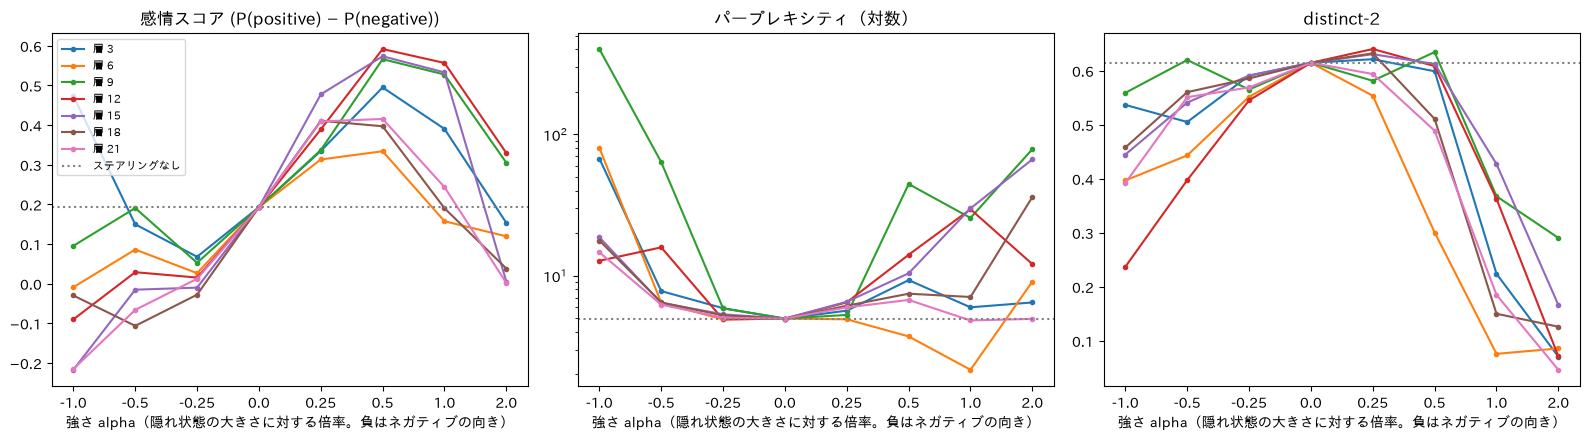

In [6]:
grid = sorted(alphas + [0.0])                          # 横軸は等間隔に並べる。alpha 0 はどの層もステアリングなしの値
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, label in zip(axes, ["sentiment", "ppl", "distinct2"], ["感情スコア (P(positive) − P(negative))", "パープレキシティ（対数）", "distinct-2"]):
    for layer in layers:
        r = results[results.layer == layer].set_index("alpha")[col]
        ax.plot(range(len(grid)), [b[col] if a == 0 else r[a] for a in grid], marker=".", label=f"層 {layer}")
    ax.axhline(b[col], color="gray", ls=":", label="ステアリングなし")
    ax.set_xticks(range(len(grid)), [str(a) for a in grid])
    ax.set_xlabel("強さ alpha（隠れ状態の大きさに対する倍率。負はネガティブの向き）"); ax.set_title(label)
axes[1].set_yscale("log"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [7]:
# 効果と崩れのバランスが良い条件: PPL がなしの 2 倍以内、distinct-2 がなしの 0.9 倍以上のうち、感情スコアが最も高いもの
ok = results[(results.alpha > 0) & (results.ppl < 2 * b.ppl) & (results.distinct2 > 0.9 * b.distinct2)]
best = ok.loc[ok.sentiment.idxmax()]
L = int(best.layer)
print(f"条件を満たすもののうち感情スコアが最も高い: 層 {L}、alpha {best.alpha}（感情スコア {best.sentiment:.3f}、PPL {best.ppl:.1f}、distinct-2 {best.distinct2:.3f}）")

# 条件を選んだのと同じ生成で差を測ると、たまたま高く出た条件を選んだぶん大きめに出る。乱数の種を変えて生成し直して測る
new_base = generate(seed=1)
with steering(steer_vec, L, best.alpha):
    new_steered = generate(seed=1)
# 差の信頼区間: プロンプト単位で復元抽出するブートストラップ（同じプロンプトの 4 本は独立ではないので）
s0 = sentiment(new_base).reshape(len(prompts), N_SAMPLES).mean(1)
s1 = sentiment(new_steered).reshape(len(prompts), N_SAMPLES).mean(1)
rng = np.random.default_rng(0)
boot = [(s1[i] - s0[i]).mean() for i in rng.integers(0, len(prompts), (2000, len(prompts)))]
print(f"生成し直した 80 本: なし {s0.mean():.3f}、あり {s1.mean():.3f}、差 {np.mean(s1 - s0):+.3f}  95% 信頼区間 [{np.percentile(boot, 2.5):+.3f}, {np.percentile(boot, 97.5):+.3f}]")

# 同じ層で強さを変えたときの生成例（同じプロンプト、同じ乱数）
for alpha in [-1.0, -0.5, 0.0, 0.5, 1.0, 2.0]:
    t = texts[(0, 0.0) if alpha == 0 else (L, alpha)]
    print(f"alpha {alpha:+.1f}: " + " / ".join(repr(t[i][:45]) for i in [0, 20]))

条件を満たすもののうち感情スコアが最も高い: 層 3、alpha 0.5（感情スコア 0.495、PPL 9.3、distinct-2 0.599）
生成し直した 80 本: なし 0.154、あり 0.429、差 +0.275  95% 信頼区間 [+0.161, +0.382]
alpha -1.0: 'でにくわしい料理でできる。の、さい、用の で な さ 用 な よ め の め の に や ' / 'でも読める。で、わかり。の、読み」で学習に!\nできる家庭科シリーズテキスト\n「大学」の入学'
alpha -0.5: '\n・ 「昨日」は「おととい」の誤り。「よ」\n「よ」は「よ」。「よ」の誤読性にすぐれた文字の' / 'でも、今まで使っていた電話会社のSIMが挿さらない。\n「SIMフリー」という言葉を聞くと、'
alpha +0.0: '\nレストランは、広くてきれいだった。\n「きれいだった」は、きれいだった。\n「きれいだった」' / 'でも、今まで使っていたスマートフォンで使っているアプリが使えなくて困ってます。\n●最近、新'
alpha +0.5: '\nレストランは、その名前に恥じるような、\n美味しいレストランだった。\nレストランの料理は、' / 'でも、今まで使っていたスマートフォンは、すぐに、また使っていきたい。\nそこで、スマートフォ'
alpha +1.0: '\nまた、素敵な思い出をありがとうございます。\nまた、また素敵な思い出をありがとうございます' / '\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n'
alpha +2.0: '\n\n\n\n\n\n\n\n\n\n\n\n' / '\n\n\n\n\n\n\n\n\n'


In [8]:
# 文体も同じ方法で変えられる: です・ます調と、だ・である調の対からベクトルを作り、です・ます調の文の割合を数える
style_pairs = [("今日は雨が降っている。", "今日は雨が降っています。"), ("この店のラーメンはおいしい。", "この店のラーメンはおいしいです。"),
               ("明日は早く起きるつもりだ。", "明日は早く起きるつもりです。"), ("駅までは歩いて十分ほどだ。", "駅までは歩いて十分ほどです。"),
               ("昨日は友達と映画を見た。", "昨日は友達と映画を見ました。"), ("この問題はとても難しい。", "この問題はとても難しいです。"),
               ("週末は家でゆっくり過ごした。", "週末は家でゆっくり過ごしました。"), ("会議は午後三時から始まる。", "会議は午後三時から始まります。"),
               ("彼は毎朝ジョギングをしている。", "彼は毎朝ジョギングをしています。"), ("その本はまだ読んでいない。", "その本はまだ読んでいません。"),
               ("夏休みに北海道へ行く予定だ。", "夏休みに北海道へ行く予定です。"), ("この部屋は少し寒い。", "この部屋は少し寒いです。")]
plain, _ = states([a for a, _ in style_pairs])
polite, _ = states([b for _, b in style_pairs])
style_vec = (polite - plain).mean(0)                   # です・ます調の向き

def polite_rate(texts):
    """文末（。で区切った各文）が「です」「ます」「でした」「ました」「ません」などで終わる割合"""
    sents = [s.strip() for t in texts for s in t.split("。")[:-1] if s.strip()]
    return np.mean([s.endswith(("です", "ます", "でした", "ました", "ません", "でしょう", "ましょう")) for s in sents]) if sents else float("nan")

print(f"ステアリングなし: です・ます調の文の割合 {polite_rate(base):.2f}  PPL {perplexity(base):.1f}  distinct-2 {distinct2(base):.3f}")
for alpha in [0.25, 0.5, 1.0]:
    with steering(style_vec, L, alpha):
        t = generate()
    print(f"層 {L}、alpha {alpha}: です・ます調の文の割合 {polite_rate(t):.2f}  PPL {perplexity(t):.1f}  distinct-2 {distinct2(t):.3f}  例: {t[0][:50]!r}")

ステアリングなし: です・ます調の文の割合 0.24  PPL 5.0  distinct-2 0.615
層 3、alpha 0.25: です・ます調の文の割合 0.77  PPL 5.4  distinct-2 0.539  例: '\nレストランは、広くて、きれいで、とてもおいしかったです。\nレストランは、広くて、きれいで、とてもき'
層 3、alpha 0.5: です・ます調の文の割合 0.82  PPL 3.8  distinct-2 0.315  例: '\nレストランに行きました。\nレストランにいきました。\nレストランに行きましtた。\nレストランに行きま'
層 3、alpha 1.0: です・ます調の文の割合 0.76  PPL 3.1  distinct-2 0.111  例: '\n\n   )に新しいレストランを、新しいレストランに、新しいレストランに、新しいレストランに、新しい'


- アクティベーション・ステアリングは、追加の学習をせずに、推論中の隠れ状態にベクトルを足して出力を変える方法である。ActAdd（Turner ら, 2023）は「Love」と「Hate」のような 1 対のプロンプトの隠れ状態の差を、ある層のプロンプトの先頭の位置に足す（GPT-2-XL などで実験）。CAA（Rimsky ら, ACL 2024。arXiv の版の第 1 著者名は Nina Panickssery）は、多数の対（A/B の選択問題の答えの記号の位置）の差の平均を Llama 2 Chat の残差ストリームに、プロンプトより後のすべての位置で足す。ここでは CAA と同じく 24 対の差の平均を使い（各文の隠れ状態はトークンで平均）、プロンプトも含むすべての位置に足した。強さは、層によって隠れ状態の大きさが違う（層 3 で 14.1、層 23 で 47.7）ので、その層の隠れ状態の大きさに対する倍率 alpha で表した。差の平均そのものの長さは隠れ状態の 0.10〜0.19 倍である。
- この実行（プロンプト 20 個 × 4 本 = 80 本、40 トークン）では、alpha 0.25 で、ステアリングなしで 0.193 の感情スコアが層によって 0.31〜0.48 になり、おおむね上がった（最も小さい層 6 の +0.12 は、後で示す信頼区間の幅（±0.11 ほど）から見てばらつきの範囲かもしれない）。PPL（4.9〜6.5、なしは 5.0）と distinct-2（0.55〜0.64、なしは 0.62）は大きくは崩れなかった。逆向きの alpha −0.25 では −0.03〜0.07 に下がった。PPL が 2 倍以内で distinct-2 が 0.9 倍以上という条件で最も感情スコアが高かったのは層 3、alpha 0.5 (0.495) だった。同じ生成で選んだ条件の差は大きめに出るので、乱数の種を変えて 80 本ずつ生成し直すと、なし 0.154、あり 0.429 で、差は +0.275（プロンプト単位のブートストラップの 95% 信頼区間 [+0.161, +0.382]）だった。ただし対の文もプロンプトも 1 組で、層と強さの探索は乱数の種 1 つの結果なので、層による 0.1 程度の違いで「この層が最適」とは言えない。CAA でも最適な層はモデルと課題ごとに探している。
- 強すぎると文が崩れる。alpha 1〜2 では「また、素敵な思い出をありがとうございます」の繰り返しや改行だけの出力が増え、alpha 2 の distinct-2 は 0.05〜0.29 まで下がった。alpha −1 の PPL は 12.7〜402 に上がった。一方、同じ語や改行の繰り返しは PPL がなしと同じくらいか、それより低くなる。層 6 の alpha 1 は PPL 2.16 (distinct-2 0.08)、層 21 の alpha 2 は PPL 4.9 でなしとほぼ同じなのに distinct-2 は 0.05 だった。PPL だけでは崩れを見落とす。分類器も崩れた文を誤判定し、層 3 の alpha −1（ネガティブの向き）は感情スコアが +0.47 になった。自動評価の数値だけで条件を選ばず、生成例を必ず読む。
- この章の「BERT の各層に品詞や構文の情報がどれくらい入っているかを調べる（プロービング）」との関係: 差の平均の方向は、最も単純な線形のプローブにあたる。計算に使っていない 16 文を射影で分けると、正解率は層 0〜10 で 0.81〜0.94、層 11〜23 で 1.00（最終の正規化の後の層 24 では 0.88）、2 群の離れ方は層 14 前後が最大だった（16 文だけなので目安）。足して効いたのは、正解率が最も高い層だけではなかった（正解率 0.88 の層 3 でも感情は変わった。ただし層 3 に足したベクトルは残差ストリームを通って後ろの層にも届く）。プロービングは「情報が読み出せる」ことまでしか示さないが、ステアリングはその方向を書き換えると出力が変わることを示す介入の実験になる。
- この章の「言語モデルのどの層で次のトークンの予測が固まるかを見る（logit lens と tuned lens）」と同じく、ベクトルを最終層の正規化と出力層で読むと、+ の向きは「嬉しい」「感謝」「素敵な」や英語の warmth、enjoyed、− の向きは「ひどい」「酷い」や worse を押し上げる方向だった。足したベクトルは最終層まで残差ストリームを通って、こうした語の確率を直接上げていると考えられる。
- 文体も同じ方法で変わった。だ・である調とです・ます調の 12 対から作ったベクトルを層 3 に足すと、です・ます調で終わる文の割合が 0.24 から 0.77 (alpha 0.25)、0.82 (alpha 0.5) に上がった。ただし alpha 0.5 ですでに「レストランに行きました。」のような同じ文の繰り返しが出始め（distinct-2 はなしの 0.62 から 0.32 に下がり、PPL 3.8 はなしの 5.0 より低い）、alpha 1 では文が崩れた (distinct-2 0.11)。この実行で繰り返しがまだ少ないのは alpha 0.25 (distinct-2 0.54) までだった。層は感情の実験で選んだものをそのまま使い、文末の判定も簡単な文字列の比較である。
- 0.5B のベースモデルは、ステアリングなしでも英訳の練習や問題集のような続きをよく出し、多言語の感情分類器はそうした文もポジティブ寄りに判定する（なしでもポジティブの割合が 0.74）。指示に従う LLM なら、まずプロンプトで指示するほうが簡単で確実である。ステアリングは、プロンプトでは変えにくい性質を調べたり、内部の表現の役割を確かめたりするのに向く。forward hook は外し忘れると以後の計算すべてに効くので、with で囲んで必ず外す（この章の logit lens のレシピの nnsight でも同じ介入が書ける）。
- モデルは SB Intuitions の Sarashina2.2-0.5B（MIT ライセンス）、感情分類器は lxyuan/distilbert-base-multilingual-cased-sentiments-student (Apache 2.0)、対の文とプロンプトは自作。トークナイザーの修正は、大規模言語モデルの章の「オープンな LLM とチャットする（チャットテンプレート）」の注意書きを参照。この実行は Ampere 以降の GPU で bfloat16 の経路を通り、GPU メモリの最大は 2.9 GB だった。